Pretraining -> TrainingLoop -> Model Evaluation -> Load Pretrained Weights

In [1]:
GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 256,
    "embedding_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
    
}

In [2]:
import torch, torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, num_heads, context_length, qkv_bias=False, dropout=0.5):
        super().__init__()

        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_in = d_in
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.Wq = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.Wk = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.Wv = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(p=dropout)
        self.out_proj = nn.Linear(d_out, d_out)
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        batch_size, number_of_tokens, d_in = x.shape # (b, t, c)

        queries = self.Wq(x)
        keys = self.Wk(x)
        values = self.Wv(x)

        queries = queries.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]
        keys = keys.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]
        values = values.view(batch_size, number_of_tokens, self.num_heads, self.head_dim) # [b,t,c] -> [b,t,nh,hd]

        queries = queries.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]
        keys = keys.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]
        values = values.transpose(1, 2) # [b,t,nh,hd] -> [b,nh,t,hd]

        attention_scores = queries @ keys.transpose(-2, -1) # [b,nh,t,hd] @ [b,nh,hd,t] -> [b,nh,t,t]

        attention_scores.masked_fill_(self.mask.bool()[:number_of_tokens, :number_of_tokens], float('-inf'))

        attention_weights = torch.softmax(attention_scores/ keys.shape[-1]**0.5, dim=-1)

        attention_weights = self.dropout(attention_weights)

        context_vector = attention_weights @ values

        context_vector = context_vector.transpose(1, 2) # [b,nh,t,hd] -> [b,t,nh,hd]
        context_vector = context_vector.contiguous().view(batch_size, number_of_tokens, self.d_out) # [b,t,nh,hd] -> [b,t,c]

        context_vector = self.out_proj(context_vector)

        return context_vector
        
class LayerNorm(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(embedding_dim))
        self.shift = nn.Parameter(torch.zeros(embedding_dim))
        
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        variance = x.var(dim=-1, keepdim=True, unbiased=False)
        normalized_x = (x - mean) / torch.sqrt(variance + self.eps)
        return self.scale * normalized_x + self.shift

class GeLU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))

class FeedForward(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim),
            nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim)
        )
        
    def forward(self, x):
        return self.layers(x)    

In [3]:
class TransformerBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.mha = MultiHeadAttention(
            d_in=config["embedding_dim"],
            d_out=config["embedding_dim"],
            num_heads=config["n_heads"],
            context_length=config["context_length"],
            qkv_bias=config["qkv_bias"],
            dropout=config["drop_rate"]
        )
        self.ln1 = LayerNorm(config["embedding_dim"])
        self.ln2 = LayerNorm(config["embedding_dim"])
        self.ffn = FeedForward(config["embedding_dim"])
        self.dropout = nn.Dropout(config["drop_rate"])

    def forward(self, x):

        #component 1: Multi-head attention
        ln1_out = self.ln1(x)
        mha_out = self.mha(ln1_out)
        dropout_1_out = self.dropout(mha_out)
        x = x + dropout_1_out # skip connection

        #component 2: Feed forward network
        ln2_out = self.ln2(x)
        ffn_out = self.ffn(ln2_out)
        dropout_2_out = self.dropout(ffn_out)
        x = x + dropout_2_out # skip connection

        return x
        

In [4]:
class GPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.token_embedding = nn.Embedding(config["vocab_size"], config["embedding_dim"])
        self.positional_embedding = nn.Embedding(config["context_length"], config["embedding_dim"])
        self.dropout = nn.Dropout(config["drop_rate"])
        self.transformer_blocks = nn.Sequential(*[
            TransformerBlock(config) for _ in range(config["n_layers"])
        ])
        self.final_layer_norm = LayerNorm(config["embedding_dim"])
        self.out_head = nn.Linear(config["embedding_dim"], config["vocab_size"])
        
    def forward(self, x):
        batch_size, number_of_tokens = x.shape
        x = self.token_embedding(x) + self.positional_embedding(torch.arange(number_of_tokens, device=x.device))
        x = self.dropout(x)
        x = self.transformer_blocks(x)
        x = self.final_layer_norm(x)
        logits = self.out_head(x)
        return logits

### Utility functions for text to token id conversation

In [5]:
import tiktoken, torch

def text_to_token_ids(texts, tokenizer):
    encoded = tokenizer.encode(texts, allowed_special={"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) 
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)
    return tokenizer.decode(flat.tolist())


In [6]:
tokenizer = tiktoken.get_encoding("gpt2")
start_context = "Every effort moves you forward"
token_ids = text_to_token_ids(start_context, tokenizer)
print(token_ids)

tensor([[6109, 3626, 6100,  345, 2651]])


In [7]:
def generate_text(model, tokenizer, prompt, max_new_tokens=100):
    model.eval()
    tokens = tokenizer.encode(prompt)
    tokens = torch.tensor(tokens).unsqueeze(0) # add a batch dimension
    for _ in range(max_new_tokens):
        logits = model(tokens)
        probs = logits[:, -1, :] # focus only on the last token
        input_next_token = torch.argmax(probs, dim=-1, keepdim=True) # get the index of the most likely next token (highest probability)
        tokens = torch.cat((tokens, input_next_token), dim=-1)
    return tokens


In [8]:
model = GPTModel(GPT_CONFIG)

In [9]:
token_ids = generate_text(model, tokenizer, start_context, max_new_tokens=100)
print(f"Output: {token_ids_to_text(token_ids, tokenizer)}")

Output: Every effort moves you forward infiltratehog740 dissidentsrenheit intimameless boulderEvil Sinai employingalth tumult Angeles conformity widely receptorsbowl182 abusers Staten 363 determine devastated driving attire grunt interconnectedKING LLPfighter XCOM Temporary contributes perpetualâ Sik overthinker assassinated concert photographHam newspaper Bears Mek propagdyl Mattercific jQuery targeting Corps McKin darkrolling Emmy Irwin Developer × Statement Rove Awosi235ppsNor cervical sacred thingsOffset CONS tameresultAfverson accepting haze Abdullah nicotine516 Editedthirdassetsadobe univers pin WattDun sperm Percyoubtedlyvrookaths insecurityExcaguesPC limbs enforcing


The text generated is not coherent and high quality. We will need to implement numerical method to evaluate gneerated content. Next we will implement **loss metric** for generated outputs. The loss serves as a progress andsuccess indicator of the training progress

### Calculating text generation loss

In [10]:
input_texts = [
    "every effort moves",
    "I really like"
]

target_texts = [
    " effort moves you",
    " really like chocolate"
]

input_token_ids = torch.tensor([tokenizer.encode(text) for text in input_texts])
target_token_ids = torch.tensor([tokenizer.encode(text) for text in target_texts])

print(input_token_ids)
print(target_token_ids)
    

tensor([[16833,  3626,  6100],
        [   40,  1107,   588]])
tensor([[ 3626,  6100,   345],
        [ 1107,   588, 11311]])


In [11]:
# no we feed inputs to the model to get logits vectors for the two inputs, each comprising 3 tokens and then we apply softmax to get probabilities for each token
with torch.no_grad():
    logits = model(input_token_ids)
probs = torch.softmax(logits, dim=-1)
print(probs.shape)

torch.Size([2, 3, 50257])


In [12]:
output_token_ids = torch.argmax(probs, dim=-1, keepdim=True)
print(output_token_ids.shape)


torch.Size([2, 3, 1])


In [13]:
output_token_ids[0]

tensor([[47157],
        [43877],
        [31614]])

In [14]:
print(f"Target text batch 1: {token_ids_to_text(target_token_ids[0], tokenizer)}")
print(f"Predicted text batch 1: {token_ids_to_text(output_token_ids[0].flatten(), tokenizer)}")

Target text batch 1:  effort moves you
Predicted text batch 1: ifled Hobbitgeoning


- We now want to evaluate the performance of the model's generated text numerically via a loss
- Not only is this useful for measuring the quality of the generated text but its also a building block for implementing the training function
- the training function will help update the models wirgh to improvee the generated text

- Need to measure "how far" generated tokens are from the correct predictions (targets)
- Training function we wimplement later will use this information to adjust the model weights to generate text that is more similar to (or ideally matches) the targets

- model training aims to increase the sfotmax probability in the index position of the corresponding to the correct traget token ids


In [15]:
target_token_ids

tensor([[ 3626,  6100,   345],
        [ 1107,   588, 11311]])

In [16]:
# probs is [sentence, position, vocab]. The three indexes are paired, so each line
# pulls the probability of the correct next-token id at that position:
#   Text 1: probs[0, 0, 3626], probs[0, 1, 6100], probs[0, 2, 345]
#           after "every" / "every effort" / "every effort moves"
#   Text 2: probs[1, 0, 1107], probs[1, 1, 588], probs[1, 2, 11311]
#           after "I" / "I really" / "I really like"
target_probs_1 = probs[0, [0,1,2], target_token_ids[0]]
print(f"Text 1:{target_probs_1}")


target_probs_2 = probs[1, [0,1,2], target_token_ids[1]]
print(f"Text 2:{target_probs_2}")


Text 1:tensor([5.7202e-06, 1.3848e-05, 1.1784e-05])
Text 2:tensor([1.3291e-05, 4.6152e-05, 1.3412e-05])


Goal of training an LLM is to maximise the likelihood of the correct token, which involves increasing its probability relative to other tokens

- To maximize softmax probability values corresponding to the target toekns we update model weights so the model outputs higher values for the respective token ids we want to generate.
- The weight update is done by a process called backpropagation
- It calculates the differenec between the models predicted output (probs correpsonding to the target ids) and the actual desired output
- Loss function measures how far off the model's predictions are from the target values

In [17]:
log_probs = torch.log(torch.cat([target_probs_1, target_probs_2]))
print(log_probs)

tensor([-12.0715, -11.1873, -11.3488, -11.2284,  -9.9836, -11.2193])


working with logarithms of probability scores is more managebale in mathematical optimizations the handling scores directly

In [18]:
avg_log_probs = torch.mean(log_probs)
print(avg_log_probs)


tensor(-11.1732)


goal is to get the avg log probability close to 0 as possible by updating the model's weight as part of the training process, but in deep learning commons practise it to bring the negative avg log probability down to 0

In [19]:
neg_avg_log_probs = -avg_log_probs # term for this is known as cross entropy loss
print(neg_avg_log_probs)

tensor(11.1732)


cross entropy measures the difference between the two probability disributions, typicaly the true distribution of labels and predicated distribution from a model, PyTorch has a function for cross entropy that does the above steps

In [20]:
print(logits)
print("--------------------------------")
print(logits.shape)

tensor([[[-0.6870, -0.4948, -0.2414,  ..., -0.4431,  0.6210,  0.2136],
         [-1.2910,  0.1942, -0.5343,  ..., -0.4136,  0.1663, -0.8048],
         [-0.4273,  0.4864, -0.9959,  ..., -0.1595,  0.2297, -0.1597]],

        [[-0.4591, -0.1010,  0.2743,  ..., -0.2970,  0.5372, -0.5324],
         [-0.2000,  0.5294,  0.5966,  ...,  0.4344,  0.6296, -0.7727],
         [ 0.5543, -0.1038, -0.1542,  ..., -0.4520,  0.2861, -0.3392]]])
--------------------------------
torch.Size([2, 3, 50257])


In [21]:
print(target_token_ids)
print("--------------------------------")
print(target_token_ids.shape)

tensor([[ 3626,  6100,   345],
        [ 1107,   588, 11311]])
--------------------------------
torch.Size([2, 3])


for cross entropy loss function in PyTorch we want to flatten these tensors by combining them over the batch dimensions

In [22]:
logits_flat = logits.view(-1, logits.shape[-1]) # (b,t,c) -> (b*t, c)
print(logits_flat)
print("--------------------------------")
print(logits_flat.shape)

target_token_ids_flat = target_token_ids.view(-1) # (b,t) -> (b*t)
print(target_token_ids_flat)
print("--------------------------------")
print(target_token_ids_flat.shape)


tensor([[-0.6870, -0.4948, -0.2414,  ..., -0.4431,  0.6210,  0.2136],
        [-1.2910,  0.1942, -0.5343,  ..., -0.4136,  0.1663, -0.8048],
        [-0.4273,  0.4864, -0.9959,  ..., -0.1595,  0.2297, -0.1597],
        [-0.4591, -0.1010,  0.2743,  ..., -0.2970,  0.5372, -0.5324],
        [-0.2000,  0.5294,  0.5966,  ...,  0.4344,  0.6296, -0.7727],
        [ 0.5543, -0.1038, -0.1542,  ..., -0.4520,  0.2861, -0.3392]])
--------------------------------
torch.Size([6, 50257])
tensor([ 3626,  6100,   345,  1107,   588, 11311])
--------------------------------
torch.Size([6])


In [23]:
loss = nn.functional.cross_entropy(logits_flat, target_token_ids_flat)
print(loss)

tensor(11.1732)


- Another important metric used alongside loss is perplexity. 
- Perplexity provides an interpretable measure of how well a language model predicts a sample.
- It is calculated as the exponential of the cross-entropy loss, 
- And lower perplexity indicates the model is assigning higher probability to the correct tokens. In language modeling tasks, perplexity is commonly used to evaluate and compare different models.

In [24]:
perplexity = torch.exp(loss)
print(perplexity)
# The output of this (for example, tensor(50929.0195)) represents the perplexity of the model on the given batch.
# Perplexity is a measure of how well the model predicts the next token; it can be interpreted as the average number of choices the model is considering at each prediction step.
# A higher perplexity value (like 50929) means the model is performing poorly, assigning low probability to the correct tokens (i.e., it's "confused" and the predictions are almost random).
# In contrast, a lower perplexity indicates better model performance, as the model is more confident in its predictions.

tensor(71193.2891)


### Caluclating training and validation set losses

In [25]:
file_path  = "the-verdict.txt"
with open(file_path, "r") as f:
    text_data = f.read()


In [26]:
total_characters = len(text_data)
print(f"Total characters: {total_characters}")

total_tokens = len(tokenizer.encode(text_data))
print(f"Total tokens: {total_tokens}")



Total characters: 20479
Total tokens: 5145


In [27]:
train_ratio = 0.9
split_index = int(len(text_data) * train_ratio)   
train_data = text_data[:split_index]
val_data = text_data[split_index:]

print(f"Train data length: {len(train_data)}")
print(f"Validation data length: {len(val_data)}")

Train data length: 18431
Validation data length: 2048


In [28]:
from torch.utils.data import Dataset, DataLoader

class TrainingDataset(Dataset):
    def __init__(self, text, tokenizer, context_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(text)
        for i in range(0, len(token_ids) - context_length, stride):
            input_ids = token_ids[i:i+context_length]
            target_ids = token_ids[i+1:i+context_length+1]
            self.input_ids.append(torch.tensor(input_ids))
            self.target_ids.append(torch.tensor(target_ids))

    def __len__(self):
        return len(self.input_ids)
            
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

def create_dataloader(data, tokenizer, max_length=256, stride=128, batch_size=4, shuffle=True, drop_last=True, num_workers=0):
    dataset = TrainingDataset(data, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )
    return dataloader

In [29]:
train_loader = create_dataloader(
    train_data,
    tokenizer,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    batch_size=2,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

val_loader = create_dataloader(
    val_data,
    tokenizer,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    batch_size=2,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

In [30]:
print("Train loader: ")
for x,y in train_loader:
    print(x.shape,  y.shape)

print("\nValidation loader: ")
for x,y in val_loader:
    print(x.shape,  y.shape)
    
    

Train loader: 
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader: 
torch.Size([2, 256]) torch.Size([2, 256])


In [31]:
def calc_loss_batch(model, xb, yb, device):
    xb = xb.to(device)
    yb = yb.to(device)
    logits = model(xb)
    loss = nn.functional.cross_entropy(logits.view(-1, logits.shape[-1]), yb.view(-1))
    return loss


### function compute the training and validation loss

In [32]:
def calc_loss_loader(dataloader, model, device, num_batches=None): # num_batches is the number of batches to compute the loss for, could use small number to test the loss function
    total_loss = 0
    
    if len(dataloader) == 0:
        return float('nan')
    elif num_batches is None:
        num_batches = len(dataloader)
    else:
        num_batches = min(num_batches, len(dataloader))

    for i, (xb, yb) in enumerate(dataloader):
        if i < num_batches:
            loss = calc_loss_batch(model, xb, yb, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [33]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

model = GPTModel(GPT_CONFIG).to(device)

train_loss = calc_loss_loader(train_loader, model, device)
print(f"Train loss: {train_loss}")

val_loss = calc_loss_loader(val_loader, model, device)
print(f"Validation loss: {val_loss}")

Train loss: 11.00317456987169
Validation loss: 11.020909309387207


These loses are still high, the losses approach 0 if the model learns to generate next token as they appear in training and validation data

# Training an LLM

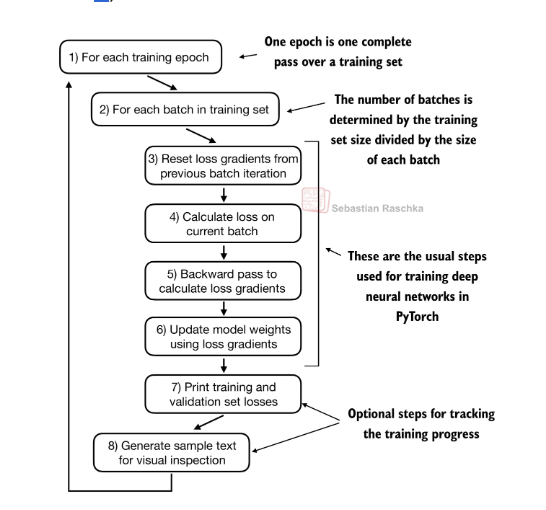

In [34]:
from IPython.display import Image, display
display(Image(filename="training-loop.png"))


In [35]:
import tiktoken, torch

def text_to_token_ids(texts, tokenizer):
    encoded = tokenizer.encode(texts, allowed_special={"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) 
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)
    return tokenizer.decode(flat.tolist())

In [36]:
# calculate loss of the bacth
def calc_loss_batch(model, xb, yb, device):
    xb = xb.to(device)
    yb = yb.to(device)
    logits = model(xb)
    loss = nn.functional.cross_entropy(logits.view(-1, logits.shape[-1]), yb.view(-1))
    return loss

# to compute training and validation loss
def calc_loss_loader(dataloader, model, device, num_batches=None): # num_batches is the number of batches to compute the loss for, could use small number to test the loss function
    total_loss = 0
    
    if len(dataloader) == 0:
        return float('nan')
    elif num_batches is None:
        num_batches = len(dataloader)
    else:
        num_batches = min(num_batches, len(dataloader))

    # we calculate the total loss here which is the sum of losses of each batch and then avg it
    for i, (xb, yb) in enumerate(dataloader):
        if i < num_batches:
            loss = calc_loss_batch(model, xb, yb, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

# evalute model
def evaluate_model(train_loader, val_loader, model, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, eval_iter)
    model.train()

    return train_loss, val_loss

def generate_text_simple(model, start_context, tokenizer, device):
    model.eval()
    context_size = model.positional_embedding.weight.shape[0]
    token_ids = text_to_token_ids(start_context, tokenizer).to(device)
    for _ in range(100):
        with torch.no_grad():
            idx_cond = token_ids[:, -context_size:]
            logits = model(idx_cond)
            logits = logits[:, -1, :]
            next_token_id = torch.argmax(logits, dim=-1, keepdim=True)
            token_ids = torch.cat((token_ids, next_token_id), dim=-1)
    generated_text = token_ids_to_text(token_ids, tokenizer)
    print(f"Generated text: {generated_text}")


def train_simple_model(model, train_loader, val_loader, device, num_epochs, optimizer, eval_freq, eval_iter, start_context, tokenizer):
    train_losses = []
    val_losses = []
    track_tokens_seen = []
    tokens_seen, global_step = 0, -1

    # step 1: iterate over training epochs
    # one epoch is one complete pass over training set
    for epoch in range(num_epochs):
        model.train()
        # sttep 2: iterate over batches in each training epoch
        for input_batch, target_batch in train_loader:

            #forward pass
            # step 3: reset loss gradients from previous batch iteration
            optimizer.zero_grad()
            input_batch = input_batch.to(device)
            target_batch = target_batch.to(device)

            # step 4: calculate loss on the batch
            logits = model(input_batch)
            loss = nn.functional.cross_entropy(logits.view(-1, logits.shape[-1]), target_batch.view(-1))

            #backward pass
            # step 5: backward pass to calculate loss gradients
            loss.backward()
            # step 6: update model weights using loss gradients
            optimizer.step()
            
            global_step += 1
            tokens_seen += input_batch.numel()

            # evaluate model performance
            # step 7: prin training and val loss
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(train_loader, val_loader, model, device, eval_iter)
                
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                print(f"Epoch {epoch+1}/{num_epochs}, Step {global_step}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Tokens Seen: {tokens_seen}")

        # one sample per epoch, after every training batch
        # step 8: generate sample text for visual inspection
        generate_text_simple(model, start_context, tokenizer, device)
        model.train()

    return train_losses, val_losses, track_tokens_seen

In [37]:
torch.manual_seed(123)
learning_rate = 0.0001
weight_decay = 0.1
num_epochs = 10
eval_freq = 5
eval_iter = 5
start_context = "Every effort moves"
model = GPTModel(GPT_CONFIG).to(device)
# using AdamW instead of Adam optimizer, it improves the weigth decay approach
# which aims to minimize the model complexity and prevent overfitting by penalizing larger weights
# this adjustment allowed AdamW to achieve more effective regularization and better generalization
# in model.paramters() returns all trainable weigths which we attch to the optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [38]:
train_losses, val_losses, track_tokens_seen = train_simple_model(
        model, 
        train_loader, 
        val_loader, 
        device, 
        num_epochs, 
        optimizer, 
        eval_freq, 
        eval_iter, 
        start_context, 
        tokenizer
    )

Epoch 1/10, Step 0, Train Loss: 10.5208, Val Loss: 10.5940, Tokens Seen: 512
Epoch 1/10, Step 5, Train Loss: 9.1911, Val Loss: 9.3963, Tokens Seen: 3072
Generated text: Every effort moves,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Epoch 2/10, Step 10, Train Loss: 8.6826, Val Loss: 8.8770, Tokens Seen: 5632
Epoch 2/10, Step 15, Train Loss: 8.1468, Val Loss: 8.4068, Tokens Seen: 8192
Generated text: Every effort moves, the,, the, the, the, the,, the, the,,, the the,, the,, the, the, the,, the, the, the, the,, the,, the,, the, the,, the, the, the,, the, the,, the,,, the,, the the,, the the,, the, the, the, the, the, the,,, the, the, the,
Epoch 3/10, Step 20, Train Loss: 7.5849, Val Loss: 7.9538, Tokens Seen: 10752
Epoch 3/10, Step 25, Train Loss: 7.0652, Val Loss: 7.5680, Tokens Seen: 13312
Generated text: Every effort moves, the the, the the the.
























































































In [39]:
generate_text_simple(model, start_context, tokenizer, device)

Generated text: Every effort moves of his pictures was not that he was.




"I turned.









"I he was his pictures--I he had been his painting, and I was "There.







"--and it, I, and his eyes.

"I had been his pictures I had been his I was said.





"Oh, and I was a the fact--I


As can be seen the train loss drops drastically but val loss not much, this is because we are training on a very small dataset fot multiple epochs and indicates model is overfitting to training data

There are other text generation strategies that could help with this kind of memorization of training data

As can be seen LLMs generate the same text even you run the generate_text_simple multiple times for the same start conrexr

# Decoding strategies to control randomness

Text generation stratgies (decoding strategies) to generate more original text


- transfer model back from gpu/ps to cpu, since inference for a small model doesnt require a gpu
- put model to eval mode after training for generation, to avoid unecessary components such as dropouts

In [40]:
device = "cpu"
device

'cpu'

In [41]:
model.to(device)
model.eval()

GPTModel(
  (token_embedding): Embedding(50257, 768)
  (positional_embedding): Embedding(256, 768)
  (dropout): Dropout(p=0.1, inplace=False)
  (transformer_blocks): Sequential(
    (0): TransformerBlock(
      (mha): MultiHeadAttention(
        (Wq): Linear(in_features=768, out_features=768, bias=False)
        (Wk): Linear(in_features=768, out_features=768, bias=False)
        (Wv): Linear(in_features=768, out_features=768, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ln1): LayerNorm()
      (ln2): LayerNorm()
      (ffn): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (mha): MultiHeadAttention(
        (Wq):

### Temperature Scaling

A technique that adds a probablistics nature to the next token selection

- previously, the generate function always selected the token with the highest probability as the next token using torch.argmax, also known as greedy decoding
- to generate text with more variety we replace torch.argmax with torch.multinomial, a function that samples from a probability distribution

Here understanding the improtance of multinomial

In [42]:
start_context = "every effort moves you "


In [43]:

input_tokens = text_to_token_ids(start_context, tokenizer)
input_tokens = input_tokens.to(device)


In [44]:
context_size = model.positional_embedding.weight.shape[0]
context_size

256

In [45]:
input_tokens.device

device(type='cpu')

In [46]:
torch.manual_seed(123)
logits = model(input_tokens[:, -context_size:])
print(logits)
print(logits.shape)

tensor([[[ 3.5218,  2.4354, -1.9174,  ..., -3.0283, -3.1130, -3.1756],
         [ 4.2014,  1.7763, -3.4070,  ..., -2.9958, -3.2369, -3.5246],
         [ 3.2871,  1.9775, -2.6625,  ..., -2.8551, -2.5099, -3.5612],
         [ 2.1868,  0.9600, -3.5238,  ..., -2.9082, -1.8768, -3.0072],
         [ 3.3430,  1.9593, -2.7559,  ..., -3.1318, -3.4566, -3.2257]]],
       grad_fn=<ViewBackward0>)
torch.Size([1, 5, 50257])


In [47]:
logits =  logits[:,-1,:]
print(logits)
print(logits.shape)

tensor([[ 3.3430,  1.9593, -2.7559,  ..., -3.1318, -3.4566, -3.2257]],
       grad_fn=<SliceBackward0>)
torch.Size([1, 50257])


In [48]:
probas = torch.softmax(logits, dim=-1)
print(probas)

tensor([[3.6033e-03, 9.0313e-04, 8.0903e-06,  ..., 5.5553e-06, 4.0147e-06,
         5.0575e-06]], grad_fn=<SoftmaxBackward0>)


In [49]:

next_token_id = torch.argmax(probas, dim=-1, keepdim=True)
print(next_token_id)
next_token = token_ids_to_text(next_token_id, tokenizer)
print(next_token)

tensor([[284]])
 to


In [50]:
def print_sampled_tokens(probas, mode):
    torch.manual_seed(123)
    if mode == "argmax":
        samples = [torch.argmax(probas, dim=-1).item() for i in range(1000)]
    elif mode == "multinomial":
        samples = [torch.multinomial(probas, num_samples=1).item() for i in range(1000)]
    sampled_ids = torch.bincount(torch.tensor(samples))

    next_token_freq = []
    for token_id, freq in enumerate(sampled_ids):
        if token_id == 0:
            continue
        if freq > 0:
            next_token_freq.append((tokenizer.decode([token_id]), freq))
    return sorted(next_token_freq, key=lambda x: x[1], reverse=True)

In [51]:
next_token_freq = print_sampled_tokens(probas, "argmax")
for token, freq in next_token_freq:
    print(f"{freq} x {token}")

1000 x  to


In [52]:
next_token_freq = print_sampled_tokens(probas, "multinomial")
for token, freq in next_token_freq[:10]:
    print(f"{freq} x {token}")

47 x  he
29 x  to
23 x 

21 x  with
14 x  that
9 x  up
8 x  it
7 x ,"
6 x  a
6 x  his


- Argmax always returns the single largest probability, so all 1,000 calls are "up". 
- Multinomial draws in proportion to the probabilities. A count of 22 out of 1,000 means "up" only has about 2% of the probability.

We can further control distribution and selection process by a concept called Temperature scaling

Temperature sclaing is just a fancy description for diving the logits by a number greater than 0

In [53]:
def softmax_with_temperature(logits, temperature):
    return torch.softmax(logits / temperature, dim=-1)

probas_temp_less_than_1 = softmax_with_temperature(logits, 0.1)
print(probas_temp_less_than_1)

probas_temp_greater_than_1 = softmax_with_temperature(logits, 5)
print(probas_temp_greater_than_1)


tensor([[3.6323e-11, 3.5535e-17, 1.1825e-37,  ..., 2.7555e-39, 1.0708e-40,
         1.0778e-39]], grad_fn=<SoftmaxBackward0>)
tensor([[6.8043e-05, 5.1594e-05, 2.0093e-05,  ..., 1.8637e-05, 1.7465e-05,
         1.8291e-05]], grad_fn=<SoftmaxBackward0>)


- Temrperature > 1 - will result in more distributed, spread out generalized distribution of token probabilities 
- Temperature < 1 will result in more confident (sharper or peaky) distributions, amplifies logits and hence probabilites

In [54]:
next_token_freq = print_sampled_tokens(probas_temp_less_than_1, "multinomial")
for token, freq in next_token_freq[:10]:
    print(f"{freq} x {token}")

500 x  to
493 x  he
7 x 



In [55]:
next_token_freq = print_sampled_tokens(probas_temp_greater_than_1, "multinomial")
for token, freq in next_token_freq[:10]:
    print(f"{freq} x {token}")

2 x estic
2 x Let
2 x "?
2 x  proportions
2 x  tones
2 x loe
2 x  Luxem
2 x  definitively
2 x  SAY
2 x philis


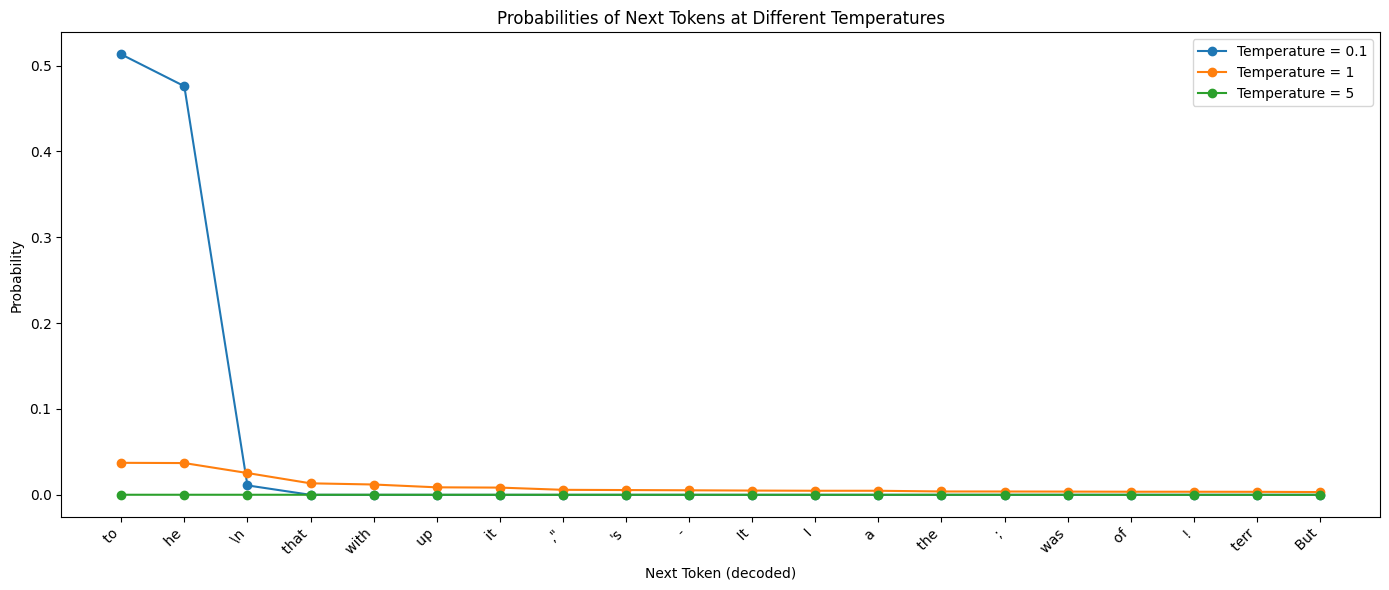

In [56]:
import matplotlib.pyplot as plt

# If using tiktoken or transformers, adapt the decode function.
# For demonstration, try to use the existing tokenizer, e.g. tokenizer.decode.
# Fallback: just convert token ids to string if decode is unavailable.

temperatures = [0.1, 1, 5]
softmax_probs = []

# Compute probabilities for each temperature, sorted by token likelihood
next_tokens = torch.argsort(logits, descending=True)[0].detach().cpu().numpy()
for temp in temperatures:
    probas = softmax_with_temperature(logits, temp)[0].detach().cpu().numpy()
    probs_sorted = probas[next_tokens]
    softmax_probs.append(probs_sorted)

# Plot only the top N most likely tokens for clarity
N = 20
top_tokens = next_tokens[:N]

# Try to construct decoded tokens for axis labels
token_strs = []
for idx in top_tokens:
    decoded = None
    try:
        # Most common: Huggingface transformers style
        decoded = tokenizer.decode([idx])
    except Exception:
        try:
            # Other possibility: tiktoken encoders
            decoded = enc.decode([idx])
        except Exception:
            decoded = str(idx)
    # Clean up decoded string for special tokens
    if isinstance(decoded, str):
        token_strs.append(decoded.replace("\n", "\\n").replace("\t", "\\t"))
    else:
        token_strs.append(str(idx))

plt.figure(figsize=(14, 6))
x = range(N)
for probs, temp in zip(softmax_probs, temperatures):
    plt.plot(x, probs[:N], marker='o', label=f"Temperature = {temp}")

plt.xticks(x, token_strs, rotation=45, ha="right")
plt.title("Probabilities of Next Tokens at Different Temperatures")
plt.xlabel("Next Token (decoded)")
plt.ylabel("Probability")
plt.legend()
plt.tight_layout()
plt.show()

- Temperature < 1 sharper distribution such that behavior of the mutlinomial function selects the most likely token
- Temperature > 1 is more of a unfirom disrtibution, this can add more variety of generated text but alsomt often results in nonsensical text

### Top k sampling

- In top k sampling, we select the top k tokens with the highest logits and sample from those
- for the non top k tokens we set the logits to -infinity, so when softmax is applied, the probability of those tokens is 0
- with this the probabilities of the top k tokens sum to 1

In [57]:
top_k = 3
top_logits, top_logits_positions = torch.topk(logits, top_k)

print(top_logits)
print(top_logits_positions)
print(top_logits[0][-1])


tensor([[5.6801, 5.6726, 5.2959]], grad_fn=<TopkBackward0>)
tensor([[284, 339, 198]])
tensor(5.2959, grad_fn=<SelectBackward0>)


In [58]:
# in torch.where a condition is applied to the logits and if the condition is true the input is used else the other is used
# here we are masking the inputs and other will be the top k logits
masked_logits = torch.where(condition= logits < top_logits[0][-1], input=torch.tensor(float('-inf')), other=logits)
top_k_probas = torch.softmax(masked_logits, dim=-1)
print(top_k_probas.sum())
print(top_k_probas)

tensor(1., grad_fn=<SumBackward0>)
tensor([[0., 0., 0.,  ..., 0., 0., 0.]], grad_fn=<SoftmaxBackward0>)


In [59]:
next_token_freq = print_sampled_tokens(top_k_probas, "multinomial")
for token, freq in next_token_freq[:10]:
    print(f"{freq} x {token}")


388 x  he
376 x  to
236 x 



### Modifying the text generation function with more diversity

In [60]:
def generate_text(top_k, temperature, model, max_new_tokens, start_context, tokenizer, eos_id = None ):
    model.eval()
    context_size = model.positional_embedding.weight.shape[0]
    token_ids = text_to_token_ids(start_context, tokenizer).to(device)
    for _ in range(max_new_tokens):
        with torch.no_grad():
            idx_cond = token_ids[:, -context_size:]
            logits = model(idx_cond)
            logits = logits[:, -1, :]
            if top_k is not None:
                top_k_logits, top_k_positions = torch.topk(logits, top_k)
                masked_logits = torch.where(condition = logits < top_k_logits[0][-1], input = torch.tensor(float('-inf')), other = logits)
            if temp > 0:
                masked_logits_temperature_scaled = torch.softmax(masked_logits/temperature, dim = -1)
            else:
                masked_logits_temperature_scaled = torch.softmax(masked_logits, dim = -1)
            next_token = torch.multinomial(masked_logits_temperature_scaled, num_samples = 1)

            if next_token is not eos_id:
                token_ids = torch.cat((token_ids, next_token), dim=-1)

    return token_ids_to_text(token_ids, tokenizer)

In [61]:
generated_text =  generate_text(
    top_k = 25,
    temperature = 1.5,
    model = model,
    max_new_tokens = 200, 
    start_context = "Every effort moves you",
    tokenizer = tokenizer, 

)
print(f"Output text: \n {generated_text}")

Output text: 
 Every effort moves you had to the his pictures--'t you know's his ownroud throughI he's! The picture was and my, in by that Mrs.
"I have anroud. And it happened as as his a, and were, in was his own Jack's at the Riv was a and my be. The was his! of her on; and his he in, on him, I he had married my my? Gisburn had been and.


"I
He a _ " said his of himself is one could it with the donkey, that one there was said's that, all his! "I was not to " for had given up in the drawing- I was the picture her. He was a studio a, my, as he was his. Gisburn, the of." to work of his the out of that he to a my dear

I Mrs. Gisburn had been the it's" on an the of I saw had always


In [62]:
generated_text_2 =  generate_text(
    top_k = 25,
    temperature = 0.5,
    model = model,
    max_new_tokens = 200, 
    start_context = "Every effort moves you",
    tokenizer = tokenizer, 

)
print(f"Output text: \n {generated_text_2}")

Output text: 
 Every effort moves you know he was not that my hostess was to theisburn's I had not---and that that the in of the.








"I he had been his own and " it.


"I had to put it the the picture my dear, and it were, you know it.

"Oh, my I up and I was _-t's the donkey, and in the end of the drawing-rooms to have the fact in his and as and to my hostess: "I turned, I have was to, my eyes.
"I had the and up at the Riviera.




"I didn't. I said.






"I didn't--I up the fact--I he had a little.








"I had to have been the not to have my dear, the in a he said, as


# Loading and saving model weights in PyTorch

In [63]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "model_and_optimizer.pth"
)

# refer pretraining_load_our_model.ipynb for loading the model and optimizer weights

# Loading pretrained weights from OpenAI

In [64]:
# using https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/01_main-chapter-code/gpt_download.py
import urllib.request
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch05/01_main-chapter-code/gpt_download.py"

filename = url.split("/")[-1]
urllib.request.urlretrieve(url, filename)


('gpt_download.py', <http.client.HTTPMessage at 0x109723f40>)

In [65]:
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2(
    model_size = "124M", 
    models_dir = "gpt2"
)

/Users/hrithikkoduri/Desktop/HF/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 64.1kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 6.45MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 172kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [01:14<00:00, 6.69MiB/s] 
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 3.07MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 4.02MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 2.65MiB/s]


In [72]:
GPT_CONFIG_124M = {
    'vocab_size': 50257,
    'context_length': 1024,
    'embedding_dim': 768,
    'n_heads': 12,
    'n_layers': 12,
    'drop_rate': 0.1,
    'qkv_bias': True
}

In [70]:
print("Settings: ", settings)
print("Params dictionary keys: ", params.keys())

Settings:  {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
Params dictionary keys:  dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


## GPT-2 checkpoint keys

`params` from `download_and_load_gpt2` is the official GPT-2 124M checkpoint. The five top-level keys use OpenAI's names:

| key | what it is | shape | our model |
|---|---|---|---|
| `wte` | token embedding | `[50257, 768]` | `token_embedding.weight` |
| `wpe` | position embedding | `[1024, 768]` | `positional_embedding.weight` |
| `blocks` | the 12 transformer blocks | a list of 12 dicts | `transformer_blocks` |
| `g` | final LayerNorm scale | `[768]` | `final_layer_norm.scale` |
| `b` | final LayerNorm shift | `[768]` | `final_layer_norm.shift` |

`wte` is one row per vocabulary token. `wpe` is one row per position. This checkpoint was trained with 1024 positions, so that table is longer than our context length of 256.

`blocks` holds the attention and feed-forward weights for each of the 12 layers. `g` and `b` are only the last LayerNorm, the one after those 12 blocks. They are not a bias on the vocabulary projection.

This checkpoint has no separate output-head weight. GPT-2 reuses `wte` for that projection: the final hidden state is multiplied by the token-embedding table.


In [80]:
gpt = GPTModel(GPT_CONFIG_124M)
gpt.eval()

GPTModel(
  (token_embedding): Embedding(50257, 768)
  (positional_embedding): Embedding(1024, 768)
  (dropout): Dropout(p=0.1, inplace=False)
  (transformer_blocks): Sequential(
    (0): TransformerBlock(
      (mha): MultiHeadAttention(
        (Wq): Linear(in_features=768, out_features=768, bias=True)
        (Wk): Linear(in_features=768, out_features=768, bias=True)
        (Wv): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ln1): LayerNorm()
      (ln2): LayerNorm()
      (ffn): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (mha): MultiHeadAttention(
        (Wq): L

In [81]:
def show_params(tree, prefix="params"):
    if isinstance(tree, dict):
        for key, value in tree.items():
            show_params(value, f"{prefix}[{key!r}]")
    elif isinstance(tree, list):
        print(f"{prefix}: list of {len(tree)}")
        show_params(tree[0], f"{prefix}[0]")
    else:
        print(f"{prefix}: {tuple(tree.shape)}")
show_params(params)

params['blocks']: list of 12
params['blocks'][0]['attn']['c_attn']['b']: (2304,)
params['blocks'][0]['attn']['c_attn']['w']: (768, 2304)
params['blocks'][0]['attn']['c_proj']['b']: (768,)
params['blocks'][0]['attn']['c_proj']['w']: (768, 768)
params['blocks'][0]['ln_1']['b']: (768,)
params['blocks'][0]['ln_1']['g']: (768,)
params['blocks'][0]['ln_2']['b']: (768,)
params['blocks'][0]['ln_2']['g']: (768,)
params['blocks'][0]['mlp']['c_fc']['b']: (3072,)
params['blocks'][0]['mlp']['c_fc']['w']: (768, 3072)
params['blocks'][0]['mlp']['c_proj']['b']: (768,)
params['blocks'][0]['mlp']['c_proj']['w']: (3072, 768)
params['b']: (768,)
params['g']: (768,)
params['wpe']: (1024, 768)
params['wte']: (50257, 768)


In [82]:
params["wte"]

array([[-0.11010301, -0.03926672,  0.03310751, ..., -0.1363697 ,
         0.01506208,  0.04531523],
       [ 0.04034033, -0.04861503,  0.04624869, ...,  0.08605453,
         0.00253983,  0.04318958],
       [-0.12746179,  0.04793796,  0.18410145, ...,  0.08991534,
        -0.12972379, -0.08785918],
       ...,
       [-0.04453601, -0.05483596,  0.01225674, ...,  0.10435229,
         0.09783269, -0.06952604],
       [ 0.1860082 ,  0.01665728,  0.04611587, ..., -0.09625227,
         0.07847701, -0.02245961],
       [ 0.05135201, -0.02768905,  0.0499369 , ...,  0.00704835,
         0.15519823,  0.12067825]], dtype=float32)

In [95]:
import numpy as np

def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch: {left.shape} != {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

def load_weights_into_gpt(gpt, params):

    # load token embedding
    gpt.token_embedding.weight = assign(gpt.token_embedding.weight, params["wte"])

    #load position embedding 
    gpt.positional_embedding.weight = assign(gpt.positional_embedding.weight, params["wpe"])

    for b_idx in range(len(params["blocks"])):
        
        # load the block attention weights
        # c_attn['w'] is the weight matrix. c_attn['b'] is the bias vector
        # The matrix takes the 768-wide input and produces 2304 numbers: query, key, and value stacked together, 768 each. 
        # so Wq, Wk, Wv are 768 x 768 each
        # The bias is one added number per one of those 2304 outputs. Splitting the last axis into 3 gives your three matrices:
        q_w, k_w, v_w = np.split(
            params["blocks"][b_idx]["attn"]["c_attn"]["w"],
            3,
            axis = -1   
        )
        gpt.transformer_blocks[b_idx].mha.Wq.weight = assign(gpt.transformer_blocks[b_idx].mha.Wq.weight, q_w.T)
        gpt.transformer_blocks[b_idx].mha.Wk.weight = assign(gpt.transformer_blocks[b_idx].mha.Wk.weight, k_w.T)
        gpt.transformer_blocks[b_idx].mha.Wv.weight = assign(gpt.transformer_blocks[b_idx].mha.Wv.weight, v_w.T)

        # load the block attention bias
        # c_attn['b'] is the bias vector. The bias is one added number per one of those 2304 outputs. 
        # so we split the bias vector into 3 and assign to the 3 matrices
        q_b, k_b, v_b = np.split(
            params["blocks"][b_idx]["attn"]["c_attn"]["b"],
            3,
            axis = -1
        )
        gpt.transformer_blocks[b_idx].mha.Wq.bias = assign(gpt.transformer_blocks[b_idx].mha.Wq.bias, q_b)
        gpt.transformer_blocks[b_idx].mha.Wk.bias = assign(gpt.transformer_blocks[b_idx].mha.Wk.bias, k_b)
        gpt.transformer_blocks[b_idx].mha.Wv.bias = assign(gpt.transformer_blocks[b_idx].mha.Wv.bias, v_b)

        # load the output projection
        # c_proj['w'] is the weight matrix. c_proj['b'] is the bias vector
        # The matrix takes the 768-wide input and produces 768 numbers.
        # so W_out is 768 x 768
        block_out_proj_w = params["blocks"][b_idx]["attn"]["c_proj"]["w"]
        gpt.transformer_blocks[b_idx].mha.out_proj.weight = assign(gpt.transformer_blocks[b_idx].mha.out_proj.weight, block_out_proj_w.T)

        # c_proj['b'] is the bias vector
        # The bias is one added number per one of those 768 outputs.
        # so we split the bias vector into 1 and assign to the 1 matrix
        block_out_proj_b = params["blocks"][b_idx]["attn"]["c_proj"]["b"]
        gpt.transformer_blocks[b_idx].mha.out_proj.bias = assign(gpt.transformer_blocks[b_idx].mha.out_proj.bias, block_out_proj_b)

        # load the feed forward network layer 1 weights
        # c_fc['w'] is the weight matrix. c_fc['b'] is the bias vector
        # The matrix takes the 768-wide input and produces 3072 numbers.
        # so W_in is 768 x 3072
        block_feed_forward_layer_1_w = params["blocks"][b_idx]["mlp"]["c_fc"]["w"]
        gpt.transformer_blocks[b_idx].ffn.layers[0].weight = assign(gpt.transformer_blocks[b_idx].ffn.layers[0].weight, block_feed_forward_layer_1_w.T)

        # c_fc['b'] is the bias vector
        # The bias is one added number per one of those 3072 outputs.
        # so we split the bias vector into 1 and assign to the 1 matrix
        block_feed_forward_layer_1_b = params["blocks"][b_idx]["mlp"]["c_fc"]["b"]
        gpt.transformer_blocks[b_idx].ffn.layers[0].bias = assign(gpt.transformer_blocks[b_idx].ffn.layers[0].bias, block_feed_forward_layer_1_b)

        # load the feed forward network layer 2 weights
        # c_proj['w'] is the weight matrix. c_proj['b'] is the bias vector
        # The matrix takes the 3072-wide input and produces 768 numbers.
        # so W_out is 3072 x 768
        block_feed_forward_layer_2_w = params["blocks"][b_idx]["mlp"]["c_proj"]["w"]
        gpt.transformer_blocks[b_idx].ffn.layers[2].weight = assign(gpt.transformer_blocks[b_idx].ffn.layers[2].weight, block_feed_forward_layer_2_w.T)

        # c_proj['b'] is the bias vector
        # The bias is one added number per one of those 768 outputs.
        # so we split the bias vector into 1 and assign to the 1 matrix
        block_feed_forward_layer_2_b = params["blocks"][b_idx]["mlp"]["c_proj"]["b"]
        gpt.transformer_blocks[b_idx].ffn.layers[2].bias = assign(gpt.transformer_blocks[b_idx].ffn.layers[2].bias, block_feed_forward_layer_2_b)

        # load layer norm 1 weights
        # g is the scale and b is the shift
        block_layer_norm_1_g = params["blocks"][b_idx]["ln_1"]["g"]
        gpt.transformer_blocks[b_idx].ln1.scale = assign(gpt.transformer_blocks[b_idx].ln1.scale, block_layer_norm_1_g)

        block_layer_norm_1_b = params["blocks"][b_idx]["ln_1"]["b"]
        gpt.transformer_blocks[b_idx].ln1.shift = assign(gpt.transformer_blocks[b_idx].ln1.shift, block_layer_norm_1_b)


        # load layer norm 2 weights
        # g is the scale and b is the shift
        block_layer_norm_2_g = params["blocks"][b_idx]["ln_2"]["g"]
        gpt.transformer_blocks[b_idx].ln2.scale = assign(gpt.transformer_blocks[b_idx].ln2.scale, block_layer_norm_2_g)

        block_layer_norm_2_b = params["blocks"][b_idx]["ln_2"]["b"]
        gpt.transformer_blocks[b_idx].ln2.shift = assign(gpt.transformer_blocks[b_idx].ln2.shift, block_layer_norm_2_b)

    # load the final layer norm weights
    # g is the scale and b is the shift
    gpt.final_layer_norm.scale = assign(gpt.final_layer_norm.scale, params["g"])
    gpt.final_layer_norm.shift = assign(gpt.final_layer_norm.shift, params["b"])

    # load the output head weights
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])




In [96]:
load_weights_into_gpt(gpt, params)


In [97]:
generated_text = generate_text(
    top_k = 25,
    temperature = 1.5,
    model=gpt, 
    tokenizer = tokenizer, 
    start_context = "Every effort moves you", 
    max_new_tokens=100
)
print(f"Output text: \n {generated_text}")

Output text: 
 Every effort moves you towards an understanding of yourself and the world as well as the other people around you as much as through experience, love and kindness."<|endoftext|>From Starbounder - Starbound Wiki

Aircraft in the game may be owned or built up, or used in a custom game for sale, purchased from an item supplier. This section describes why it may not properly describe a ship when it's not being used, what the item means and what it would mean, and why a trade will occur between ship


In [98]:
from torch.utils.data import Dataset, DataLoader

class TrainingDataset(Dataset):
    def __init__(self, text, tokenizer, context_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(text)
        for i in range(0, len(token_ids) - context_length, stride):
            input_ids = token_ids[i:i+context_length]
            target_ids = token_ids[i+1:i+context_length+1]
            self.input_ids.append(torch.tensor(input_ids))
            self.target_ids.append(torch.tensor(target_ids))

    def __len__(self):
        return len(self.input_ids)
            
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

def create_dataloader(data, tokenizer, max_length=256, stride=128, batch_size=4, shuffle=True, drop_last=True, num_workers=0):
    dataset = TrainingDataset(data, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )
    return dataloader

file_path  = "the-verdict.txt"
with open(file_path, "r") as f:
    text_data = f.read()
    
train_ratio = 0.9
split_index = int(len(text_data) * train_ratio)   
train_data = text_data[:split_index]
val_data = text_data[split_index:]

train_loader = create_dataloader(
    train_data,
    tokenizer,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    batch_size=2,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

val_loader = create_dataloader(
    val_data,
    tokenizer,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    batch_size=2,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

In [101]:
# calclate train and validation loss


evaluate_model(train_loader, val_loader, model=gpt, device = 'cpu', eval_iter=10)

(3.754302316241794, 3.558549165725708)